# TAHAP 1 - CLEANING

Membuang gambar yang tidak layak dipakai, **tanpa mengubah** `dataset_sumber_asli/`.

| Alasan ditolak | Arti |
|---|---|
| `varian_lama` | file hasil pengayaan lama (`__gerak_horizontal`, `__gerak_vertikal`, `__gerak_diagonal`, `__getar`); pengayaan dibuat ulang di tahap 4 dari foto asli |
| `rusak` | file tidak bisa dibuka |
| `duplikat` | file identik (MD5) atau hampir kembar (dHash) dalam satu kelas |
| `gelap_terang` | rata-rata keabuan hampir hitam / hampir putih (histogram, Acara 10-12) |
| `blur_parah` | tepi hilang di SEMUA arah (gradien Sobel, Acara 29) |

Blur gerak dan blur ringan sengaja **dipertahankan**: rompi dipakai sambil berjalan, jadi foto goyang adalah data yang berguna.

**Letak file:** simpan notebook ini di `notebooks/`, sedangkan `config.py`, `util.py`, `bkpm.py` ada di `scripts/`.

## 1. Setup dan import

In [5]:
import sys, os
from pathlib import Path

# folder scripts/ (berisi config.py, util.py, bkpm.py) ada di sebelah folder notebooks/
SCRIPTS = Path.cwd().resolve().parent / "scripts"
if not SCRIPTS.is_dir():                      # bila notebook dijalankan dari folder scripts/ sendiri
    SCRIPTS = Path.cwd().resolve()
sys.path.insert(0, str(SCRIPTS))

# Opsional: bila folder proyek bukan induk dari scripts/, hilangkan tanda # dan isi path-nya
# os.environ["PROYEK_ROOT"] = r"D:\rompi-cerdas-fin"

import hashlib, re, shutil
import cv2
import numpy as np
from IPython.display import Image, display

import bkpm
from config import CLASSES, D_CLEAN, SUMBER_DIR, UKURAN_MAKS, ROOT
from util import (baca_gambar, bersihkan, daftar_gambar, log, nama_aman, simpan_gambar, tabel, tulis_csv)

TAHAP = "01_cleaning"
print("Folder scripts :", SCRIPTS)
print("Folder proyek  :", ROOT)
print("Sumber foto    :", SUMBER_DIR, "| ada:", SUMBER_DIR.is_dir())
print("Folder hasil   :", D_CLEAN)
print("Kelas          :", CLASSES)
print("Sisi maks      :", UKURAN_MAKS, "px")

Folder scripts : C:\Projek\vestcare-dataset\scripts
Folder proyek  : C:\Projek\vestcare-dataset
Sumber foto    : C:\Projek\vestcare-dataset\dataset_sumber_asli | ada: True
Folder hasil   : C:\Projek\vestcare-dataset\hasil\01_cleaning
Kelas          : ['pohon', 'lubang', 'orang', 'motor', 'mobil']
Sisi maks      : 640 px


## 2. Parameter

Setara argumen CLI skrip asli (`--kelas`, `--blur-parah`, `--simpan-varian-lama`, `--mirip`). Ubah di sini lalu jalankan ulang sel-sel berikutnya.

In [6]:
KELAS_TERPILIH = None        # None = semua kelas; atau mis. "orang"
BLUR_PARAH = 40.0            # buang jika ketajaman < nilai ini (makin besar makin ketat)
SIMPAN_VARIAN_LAMA = False   # True = jangan buang file varian pengayaan lama
MIRIP = 5                    # jarak dHash (0-64) <= nilai ini dianggap duplikat

POLA_VARIAN_LAMA = re.compile(r"__(gerak_horizontal|gerak_vertikal|gerak_diagonal|getar)$", re.I)
KOLOM = ["kelas", "file_sumber", "status", "alasan", "file_hasil", "lebar", "tinggi", "rata_keabuan",
         "ketajaman", "mirip_dengan"]

kelas_list = [KELAS_TERPILIH] if KELAS_TERPILIH else CLASSES
print("Kelas diproses:", kelas_list)

Kelas diproses: ['pohon', 'lubang', 'orang', 'motor', 'mobil']


## 3. Fungsi pengukur

- `md5_file` : sidik jari file untuk duplikat identik
- `dhash` / `hamming` : sidik jari visual untuk duplikat hampir kembar
- `ketajaman` : gradien Sobel (Acara 29) pada arah paling tajam
- `simpan_bersih` : simpan hasil dengan sisi terpanjang <= `UKURAN_MAKS` (tidak di-upscale)

In [7]:
def md5_file(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(1 << 20), b""):
            h.update(blok)
    return h.hexdigest()


def dhash(gray, ukuran=8):
    """Sidik jari gambar: bandingkan tiap piksel dengan tetangga kanannya pada citra 9x8."""
    kecil = cv2.resize(gray, (ukuran + 1, ukuran), interpolation=cv2.INTER_AREA)
    bit = (kecil[:, 1:] > kecil[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bit), 2)


def hamming(a, b):
    return bin(a ^ b).count("1")


def ketajaman(gray):
    """Gradien Sobel (Acara 29) pada arah paling tajam. Makin besar makin tajam."""
    h, w = gray.shape
    s = 640.0 / max(h, w)
    if s < 1:
        gray = cv2.resize(gray, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    g = gray.astype(np.float32)
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3) / 8.0
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3) / 8.0
    terkuat = 0.0
    for sudut in np.arange(0, 180, 22.5):
        t = np.deg2rad(sudut)
        terkuat = max(terkuat, float(np.percentile(np.abs(gx * np.cos(t) + gy * np.sin(t)), 99)))
    return terkuat * 3.0


def simpan_bersih(img, tujuan):
    h, w = img.shape[:2]
    s = min(1.0, UKURAN_MAKS / max(h, w))
    if s < 1.0:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    simpan_gambar(tujuan, img, 95)


def tampil(img, maks=420):
    """Tampilkan citra BGR langsung di notebook (tanpa matplotlib)."""
    h, w = img.shape[:2]
    s = min(1.0, maks / max(h, w))
    if s < 1.0:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    display(Image(data=cv2.imencode(".png", img)[1].tobytes()))


def tampil_baris(daftar, tinggi=170, per_baris=5):
    """daftar = [(citra BGR, teks)]; disusun berdampingan, per_baris gambar tiap baris."""
    for i in range(0, len(daftar), per_baris):
        ubin = []
        for im, teks in daftar[i:i + per_baris]:
            s = tinggi / im.shape[0]
            t = cv2.resize(im, (max(1, int(im.shape[1] * s)), tinggi), interpolation=cv2.INTER_AREA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0, 0, 0), 3, cv2.LINE_AA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            ubin.append(t)
        display(Image(data=cv2.imencode(".png", np.hstack(ubin))[1].tobytes()))

print("fungsi siap")

fungsi siap


## 4. Inventaris foto sumber

Hitung jumlah file per kelas di `dataset_sumber_asli/` sebelum dibersihkan (termasuk berapa yang berupa varian pengayaan lama).

In [8]:
def folder_kelas(kelas):
    if not SUMBER_DIR.is_dir():
        return None
    return next((d for d in SUMBER_DIR.iterdir() if d.is_dir() and d.name.lower() == kelas), None)

inv = []
for k in kelas_list:
    f = folder_kelas(k)
    if f is None:
        inv.append({"kelas": k, "folder": "TIDAK ADA", "total": 0, "varian_lama": 0, "asli": 0})
        continue
    fs = daftar_gambar(f)
    lama = sum(bool(POLA_VARIAN_LAMA.search(p.stem)) for p in fs)
    inv.append({"kelas": k, "folder": f.name, "total": len(fs), "varian_lama": lama, "asli": len(fs) - lama})
tabel("Inventaris foto sumber", inv, ["kelas", "folder", "total", "varian_lama", "asli"])


Inventaris foto sumber
kelas   folder  total  varian_lama  asli
pohon   pohon   187    0            187 
lubang  lubang  319    0            319 
orang   orang   126    0            126 
motor   motor   220    0            220 
mobil   mobil   200    0            200 


## 5. Contoh uji ukur pada satu gambar

Memperlihatkan nilai yang dipakai sebagai dasar keputusan: rata-rata keabuan, ketajaman Sobel, MD5, dan dHash.

File           : primer-pohon-1.jpg
Ukuran         : 312 x 416
Rata keabuan   : 120.6 (ditolak bila < 25 atau > 235)
Ketajaman      : 143.6 (ditolak bila < 40.0)
MD5            : 7960f94770d73a9a5ee38d4fd3739e98
dHash          : 3c5e2e2e21514141


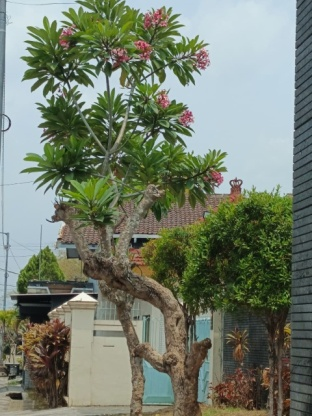

In [9]:
contoh = None
for k in kelas_list:
    f = folder_kelas(k)
    fs = daftar_gambar(f) if f else []
    if fs:
        contoh = fs[0]
        break

if contoh is None:
    print("Tidak ada gambar sumber. Periksa folder dataset_sumber_asli/.")
else:
    img = baca_gambar(contoh)
    gray = bkpm.rgb2gray(img)
    print("File           :", contoh.name)
    print("Ukuran         :", img.shape[1], "x", img.shape[0])
    print("Rata keabuan   :", round(float(gray.mean()), 1), "(ditolak bila < 25 atau > 235)")
    print("Ketajaman      :", round(ketajaman(gray), 1), f"(ditolak bila < {BLUR_PARAH})")
    print("MD5            :", md5_file(contoh))
    print("dHash          :", format(dhash(cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA)), "016x"))
    tampil(img)

## 6. Proses cleaning

Urutan keputusan per gambar (sama dengan skrip asli):
1. `varian_lama` -> 2. `rusak` -> 3. `duplikat` (MD5) -> 4. `gelap_terang` -> 5. `blur_parah` -> 6. `duplikat` (dHash)

> Sel ini **menghapus dan membuat ulang** `hasil/01_cleaning/`. Foto sumber tidak disentuh.

In [10]:
bersihkan(D_CLEAN)
laporan, nama_terpakai = [], set()

for kelas in kelas_list:
    folder = folder_kelas(kelas)
    if folder is None:
        log(TAHAP, f"folder '{kelas}' tidak ada di {SUMBER_DIR}, dilewati")
        continue
    md5_ada, hash_ada = {}, []
    files = daftar_gambar(folder)
    log(TAHAP, f"{kelas}: {len(files)} file")
    for n, p in enumerate(files, 1):
        row = {"kelas": kelas, "file_sumber": p.name, "status": "bersih", "alasan": ""}
        img = baca_gambar(p)
        md5 = md5_file(p)
        alasan, mirip = "", ""
        if not SIMPAN_VARIAN_LAMA and POLA_VARIAN_LAMA.search(p.stem):
            alasan = "varian_lama"
        elif img is None:
            alasan = "rusak"
        else:
            gray = bkpm.rgb2gray(img)
            row.update(lebar=img.shape[1], tinggi=img.shape[0], rata_keabuan=f"{gray.mean():.1f}")
            dh = dhash(cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA))
            tajam = ketajaman(gray)
            row["ketajaman"] = f"{tajam:.1f}"
            if md5 in md5_ada:
                alasan, mirip = "duplikat", md5_ada[md5]
            elif gray.mean() < 25 or gray.mean() > 235:
                alasan = "gelap_terang"
            elif tajam < BLUR_PARAH:
                alasan = "blur_parah"
            else:
                for h2, f2 in hash_ada:
                    if hamming(dh, h2) <= MIRIP:
                        alasan, mirip = "duplikat", f2
                        break
        nama = f"{kelas}_{nama_aman(p.stem)}.jpg"
        if (kelas, nama) in nama_terpakai:
            nama = f"{kelas}_{nama_aman(p.stem)}-{md5[:6]}.jpg"
        nama_terpakai.add((kelas, nama))
        row["file_hasil"], row["mirip_dengan"] = nama, mirip
        if alasan:
            row["status"], row["alasan"] = "ditolak", alasan
            tujuan = D_CLEAN / "ditolak" / alasan / kelas / nama
            tujuan.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(p, tujuan)
        else:
            md5_ada[md5] = p.name
            hash_ada.append((dh, p.name))
            simpan_bersih(img, D_CLEAN / "bersih" / kelas / nama)
        laporan.append(row)
        if n % 100 == 0:
            log(TAHAP, f"  {kelas}: {n}/{len(files)}")

print(f"\nTotal gambar diproses: {len(laporan)}")

[01_cleaning] pohon: 187 file
[01_cleaning]   pohon: 100/187
[01_cleaning] lubang: 319 file
[01_cleaning]   lubang: 100/319
[01_cleaning]   lubang: 200/319
[01_cleaning]   lubang: 300/319
[01_cleaning] orang: 126 file
[01_cleaning]   orang: 100/126
[01_cleaning] motor: 220 file
[01_cleaning]   motor: 100/220
[01_cleaning]   motor: 200/220
[01_cleaning] mobil: 200 file
[01_cleaning]   mobil: 100/200
[01_cleaning]   mobil: 200/200

Total gambar diproses: 1052


## 7. Simpan laporan dan ringkasan

In [11]:
tulis_csv(D_CLEAN / "laporan_cleaning.csv", laporan, KOLOM)

ring = []
for k in kelas_list:
    r = [x for x in laporan if x["kelas"] == k]
    if r:
        ring.append({"kelas": k, "total": len(r),
                     **{a: sum(x["alasan"] == a for x in r) for a in ("varian_lama", "duplikat", "blur_parah", "gelap_terang", "rusak")},
                     "LOLOS": sum(x["status"] == "bersih" for x in r)})
if ring:
    tot = {"kelas": "TOTAL"}
    for kol in ("total", "varian_lama", "duplikat", "blur_parah", "gelap_terang", "rusak", "LOLOS"):
        tot[kol] = sum(x[kol] for x in ring)
    ring.append(tot)
tabel("Ringkasan cleaning", ring, ["kelas", "total", "varian_lama", "duplikat", "blur_parah", "gelap_terang", "rusak", "LOLOS"])
log(TAHAP, f"laporan -> {D_CLEAN / 'laporan_cleaning.csv'}")


Ringkasan cleaning
kelas   total  varian_lama  duplikat  blur_parah  gelap_terang  rusak  LOLOS
pohon   187    0            0         0           0             0      187  
lubang  319    0            2         0           0             0      317  
orang   126    0            3         0           0             0      123  
motor   220    0            0         0           0             0      220  
mobil   200    0            0         0           0             0      200  
TOTAL   1052   0            5         0           0             0      1047 
[01_cleaning] laporan -> C:\Projek\vestcare-dataset\hasil\01_cleaning\laporan_cleaning.csv


## 8. Sebaran ketajaman dan keabuan

Membantu menyetel `BLUR_PARAH`: lihat di mana gambar yang ditolak berada dibanding yang lolos.

In [12]:
def angka(rows, kol):
    return np.array([float(x[kol]) for x in rows if x.get(kol) not in ("", None)])

print(f"{'kelas':8s} {'status':8s} {'n':>5s} {'tajam min':>10s} {'median':>8s} {'maks':>8s} {'abu rata':>9s}")
for k in kelas_list:
    for st in ("bersih", "ditolak"):
        rr = [x for x in laporan if x["kelas"] == k and x["status"] == st]
        t = angka(rr, "ketajaman")
        g = angka(rr, "rata_keabuan")
        if len(t):
            print(f"{k:8s} {st:8s} {len(rr):5d} {t.min():10.1f} {np.median(t):8.1f} {t.max():8.1f} {g.mean():9.1f}")
print(f"\nAmbang blur_parah saat ini: {BLUR_PARAH}")

kelas    status       n  tajam min   median     maks  abu rata
pohon    bersih     187       89.2    143.6    219.8     129.6
lubang   bersih     317       51.8    135.0    276.4     120.5
lubang   ditolak      2      132.0    134.8    137.6      99.8
orang    bersih     123       61.8    134.2    220.9     142.0
orang    ditolak      3       82.9    108.0    125.2     166.8
motor    bersih     220      129.0    221.1    325.1     129.5
mobil    bersih     200       44.6    164.9    240.8     115.8

Ambang blur_parah saat ini: 40.0


## 9. Galeri gambar yang ditolak

Periksa dengan mata, apakah penolakannya masuk akal. Untuk `duplikat`, label menampilkan file yang dianggap kembarannya.


== duplikat | lubang (2 file) ==


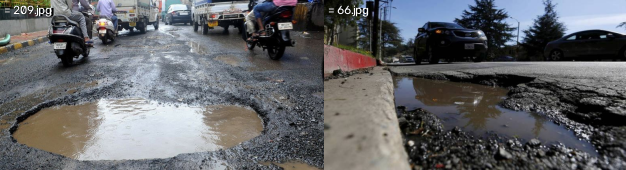


== duplikat | orang (3 file) ==


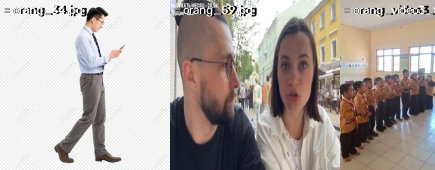

In [13]:
MAKS_CONTOH = 5   # contoh per alasan per kelas

ADA = False
for alasan in ("varian_lama", "duplikat", "blur_parah", "gelap_terang", "rusak"):
    for k in kelas_list:
        rr = [x for x in laporan if x["kelas"] == k and x["alasan"] == alasan][:MAKS_CONTOH]
        if not rr:
            continue
        ADA = True
        print(f"\n== {alasan} | {k} ({sum(x['kelas'] == k and x['alasan'] == alasan for x in laporan)} file) ==")
        galeri = []
        for x in rr:
            im = baca_gambar(D_CLEAN / "ditolak" / alasan / k / x["file_hasil"])
            if im is None:
                print("  (tidak bisa dibuka)", x["file_sumber"])
                continue
            if alasan == "duplikat":
                ket = "= " + x["mirip_dengan"][:16]
            elif alasan == "blur_parah":
                ket = f"tajam {x.get('ketajaman', '?')}"
            elif alasan == "gelap_terang":
                ket = f"abu {x.get('rata_keabuan', '?')}"
            else:
                ket = x["file_sumber"][:18]
            galeri.append((im, ket))
        if galeri:
            tampil_baris(galeri)
if not ADA:
    print("Tidak ada gambar yang ditolak.")

## 10. Galeri gambar yang lolos


== pohon: 187 gambar bersih ==


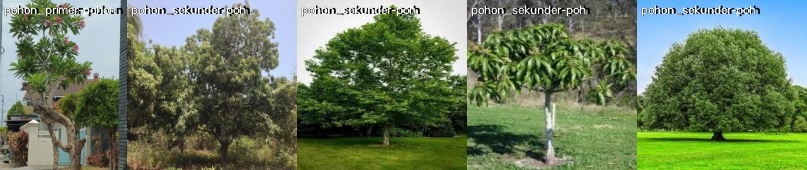


== lubang: 317 gambar bersih ==


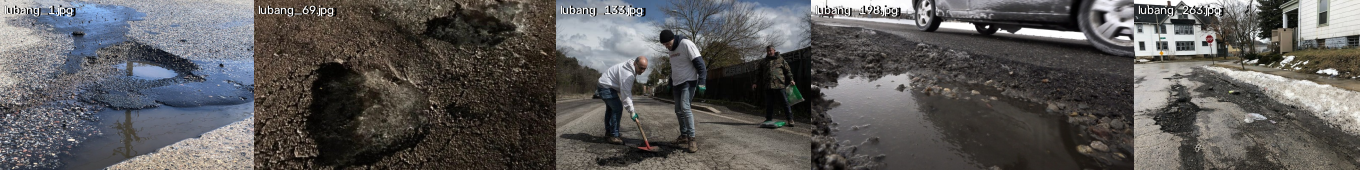


== orang: 123 gambar bersih ==


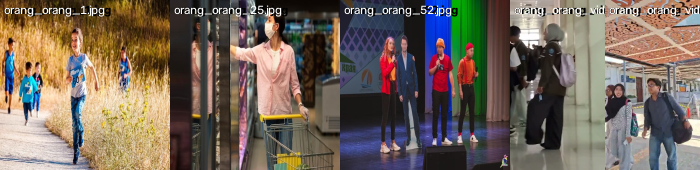


== motor: 220 gambar bersih ==


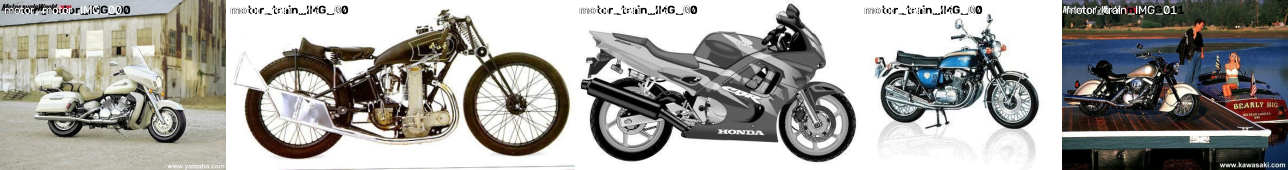


== mobil: 200 gambar bersih ==


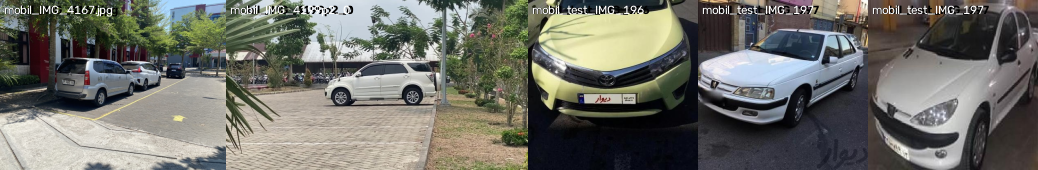

In [14]:
for k in kelas_list:
    fs = daftar_gambar(D_CLEAN / "bersih" / k)
    print(f"\n== {k}: {len(fs)} gambar bersih ==")
    if fs:
        pilih = fs[::max(1, len(fs) // 5)][:5]
        tampil_baris([(baca_gambar(p), p.name[:18]) for p in pilih])

## 11. Pemeriksaan akhir

Memastikan keluaran siap dipakai tahap 2 (`hasil/01_cleaning/bersih/<kelas>/*.jpg`).

In [15]:
lolos = sum(1 for x in laporan if x["status"] == "bersih")
ukuran_ok = True
for k in kelas_list:
    for p in daftar_gambar(D_CLEAN / "bersih" / k):
        h, w = baca_gambar(p).shape[:2]
        if max(h, w) > UKURAN_MAKS:
            ukuran_ok = False
print("Gambar bersih          :", lolos)
print("Semua sisi <= ", UKURAN_MAKS, "px :", ukuran_ok)
print("Laporan CSV            :", (D_CLEAN / "laporan_cleaning.csv").exists())
print("Folder bersih          :", D_CLEAN / "bersih")
log(TAHAP, f"selesai -> {D_CLEAN}")
print("\nLanjut ke notebook 02_segmentasi.ipynb")

Gambar bersih          : 1047
Semua sisi <=  640 px : True
Laporan CSV            : True
Folder bersih          : C:\Projek\vestcare-dataset\hasil\01_cleaning\bersih
[01_cleaning] selesai -> C:\Projek\vestcare-dataset\hasil\01_cleaning

Lanjut ke notebook 02_segmentasi.ipynb
